# M01 gravity station corrections: a traceable calculation

**Question:** How do the WGS84 reference and infinite-plate terms change the authored station value, and how much does the uncertainty policy change reported standard uncertainty?

**Level 2 · Prerequisites: the preceding foundations lesson; estimated reading time: 55 minutes.**

## Objectives

Execute the complete M01 transformation, inspect each recorded increment, test uncertainty choices, and exercise duplicate-state rejection.

## Setup

Use the repository's pinned Python 3.12 environment. Build it from the repository root with `scripts/setup.ps1 -Notebooks` on Windows or `scripts/setup.sh --notebooks` on Linux/macOS. This command is shown for reference; the notebook does not install packages.

```text
pip install boule==0.5.0 harmonica==0.7.0
```

Import the product method and plotting tools once. The next cell reports the active implementation.

In [1]:
# Import the M01 pipeline and plotting tools.
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
from gravity_processing import process_survey
from importlib.metadata import version
print('Boule:', version('boule'), '| Harmonica:', version('harmonica'))
print('Pipeline:', Path(process_survey.__code__.co_filename).name)


Boule: 0.5.0 | Harmonica: 0.7.0
Pipeline: gravity_processing.py


## Data

The lesson reads the one-station analytic control at `docs/methods/gravity-processing/examples/station-control.json`. CAOS_Geophysics authored the synthetic_control under Apache-2.0; the source citation records its defining parameters. The named pipeline is `data-pipeline/gravity_processing.py`, using Boule and Harmonica. The control is WGS84, ellipsoidal metres, tide-free, and absolute gravity in downward-positive mGal. Its 12 mGal residual is analytically authored, not measured.

Read the declared inputs or construct the authored synthetic geometry. No solver output is loaded.

In [2]:
# Read committed analytic control and retain its provenance metadata.
from copy import deepcopy
import json
control_path = root / 'docs/methods/gravity-processing/examples/station-control.json'
request = json.loads(control_path.read_text(encoding='utf-8'))
source = request['dataset']
config = request['config']
print(source['metadata']['source_kind'], source['metadata']['rights'])
print(source['metadata']['height_datum'], source['metadata']['gravity_unit'])


synthetic_control Authored numerical control, Apache-2.0
ellipsoidal mGal


## Method

### Admit the declared source

The processor validates schema, coordinates, units, sign, reference ellipsoid, height datum, instrument-correction state, and source digest before changing values. That validation is part of the method: without it the correction is underdetermined. This analytic input marks calibration applied and drift/tide not applicable. A field import with unknown calibration must be rejected rather than normalized by guesswork.

### Establish the reference disturbance

The reference stage evaluates WGS84 normal gravity at declared latitude and receiver height, then forms observed minus normal gravity under the canonical downward-positive convention. Boule implements γ(φ,h). The receiver elevation is 1000 m; it is not the same operation as subtracting a 1000 m slab. Reference choice and vertical datum can introduce offsets that resemble geology.

### Apply the plate term

The configuration declares target `bouguer_disturbance`, density 2670 kg/m³, density SD 20 kg/m³ and policy `conservative_marginals`. The processor evaluates an infinite horizontal plate and records its increment. This approximation assumes homogeneous density and infinite lateral extent; it is not a DEM terrain correction. Harmonica documents the plate calculation, while the product supplies admissibility, signs, uncertainty and lineage.

### Compare uncertainty policies

The supported policies aggregate first-order marginal contributions differently. They are conditional error calculations, not empirical confidence. Re-running with `independent_first_order` changes only aggregation; source values and physical correction remain fixed. Density uncertainty contributes to the plate stage. Correlation and datum uncertainty are not modeled, so the reported standard deviation must retain its policy label.

### Challenge the state machine

A corrected dataset carries its state and ordered history. The API must refuse a second pass from a derived state because that could apply reference or plate terms twice. This negative control verifies the state transition contract. Rejection is useful scientific behavior: an apparently repeatable request cannot silently turn a valid anomaly into a biased quantity.

### Interpret the output with limits

The increment plot and policy comparison come from actual `process_survey` calls. Check whether the final value is compatible with the authored 12 mGal residual and whether history contains three ordered operations. Agreement tests arithmetic and conventions only. It does not assess survey completeness, terrain, instrumental corrections, regional field or geological interpretation.

### Uncertainty remains conditional

First-order propagation differentiates the computed quantity with respect to specified input errors. It excludes unknown correlation, model misspecification, finite-plate effects, terrain residual, datum conversion errors and source selection. Choosing the smaller number because it looks more precise would not be a valid uncertainty analysis.

### Uncertainty derivative and units

For derived quantity q(x), first-order propagation approximates Var(q) from input covariance and the gradient of q. The processor separates gravity, latitude, receiver-height, surface-height, density and geoid contributions where applicable. Here ellipsoidal heights mean no geoid term is added. The plate-density term depends on density SD and surface-height SD. Marginal SDs cannot express covariance, so the policy label remains part of the result. Before interpreting it, check which inputs are nonzero and whether independence matches how measurements were produced.

### Uncertainty derivative and units

For derived quantity q(x), first-order propagation approximates Var(q) from input covariance and the gradient of q. The processor separates gravity, latitude, receiver-height, surface-height, density and geoid contributions where applicable. Here ellipsoidal heights mean no geoid term is added. The plate-density term depends on density SD and surface-height SD. Marginal SDs cannot express covariance, so the policy label remains part of the result.

Run the reference stage and inspect the intermediate disturbance before plate removal.

In [3]:
# Execute M01 for the reference case.
stage_config = {**config, 'target': 'gravity_disturbance'}
reference_result = process_survey(deepcopy(source), stage_config)
print('reference:', reference_result['qc']['derived_mgal'][0], 'mGal, SD =',
      reference_result['processing']['uncertainty_mgal'][0])

reference: 123.96875606756657 mGal, SD = 0.25420737094242346


Execute the declared Bouguer correction and retain the complete ordered history.

In [4]:
# Execute M01 for the conservative case.
stage_config = config
conservative_result = process_survey(deepcopy(source), stage_config)
print('conservative:', conservative_result['qc']['derived_mgal'][0], 'mGal, SD =',
      conservative_result['processing']['uncertainty_mgal'][0])

conservative: 12.000000000024315 mGal, SD = 1.148909022890369


Change only uncertainty aggregation and recompute the physical transform.

In [5]:
# Execute M01 for the independent case.
stage_config = {**config, 'uncertainty_model': 'independent_first_order'}
independent_result = process_survey(deepcopy(source), stage_config)
print('independent:', independent_result['qc']['derived_mgal'][0], 'mGal, SD =',
      independent_result['processing']['uncertainty_mgal'][0])

independent: 12.000000000024315 mGal, SD = 0.8604422289723038


Increase assumed plate density by 100 kg/m³. This isolates density sensitivity; it is not a revised estimate.

In [6]:
# Execute M01 for the denser plate case.
stage_config = {**config, 'density_kg_m3': config['density_kg_m3'] + 100.0}
denser_plate_result = process_survey(deepcopy(source), stage_config)
print('denser_plate:', denser_plate_result['qc']['derived_mgal'][0], 'mGal, SD =',
      denser_plate_result['processing']['uncertainty_mgal'][0])

denser_plate: 7.806413630453463 mGal, SD = 1.1510058160751544


Attempt to correct an already derived dataset. The product state machine should refuse duplicate reference or plate operations.

In [7]:
# Verify the product refuses a second correction pass.
try:
    process_survey(conservative_result['dataset'], config)
except ValueError as error:
    duplicate_refusal = str(error)
    print('Expected refusal:', duplicate_refusal)
else:
    raise AssertionError('Second correction pass was accepted')

Expected refusal: config.target: double correction or backwards processing rejected


Plot the stage increments recorded by the production processor, not values reconstructed from a displayed answer.

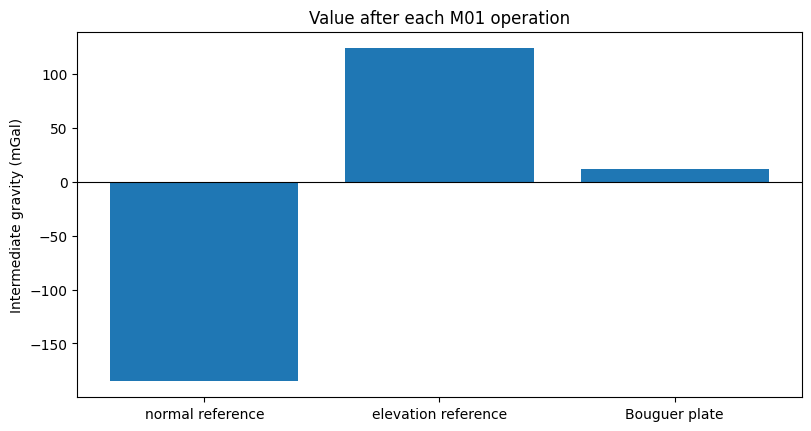

stages: ['normal_reference', 'elevation_reference', 'bouguer_plate']


In [8]:
# Plot each intermediate value after the corresponding recorded correction.
history = conservative_result['dataset']['history']
increments = [record['additions_mgal'][0] for record in history]
stage_values = source['stations'][0]['value_mgal'] + np.cumsum(increments)
fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
ax.bar(['normal reference', 'elevation reference', 'Bouguer plate'], stage_values)
ax.axhline(0.0, color='black', linewidth=0.8)
ax.set(ylabel='Intermediate gravity (mGal)', title='Value after each M01 operation')
plt.show()
print('stages:', [record['name'] for record in history])

Each bar is the intermediate station quantity after applying one recorded operation, computed from the original value plus cumulative pipeline increments. The absolute input is intentionally excluded so its roughly 980,000 mGal magnitude cannot hide the anomaly-scale transitions. This is a single analytic station sequence, not a spatial Bouguer map.

Separate the physical parameter perturbation from uncertainty aggregation. The next figure uses actual processor outputs for both.

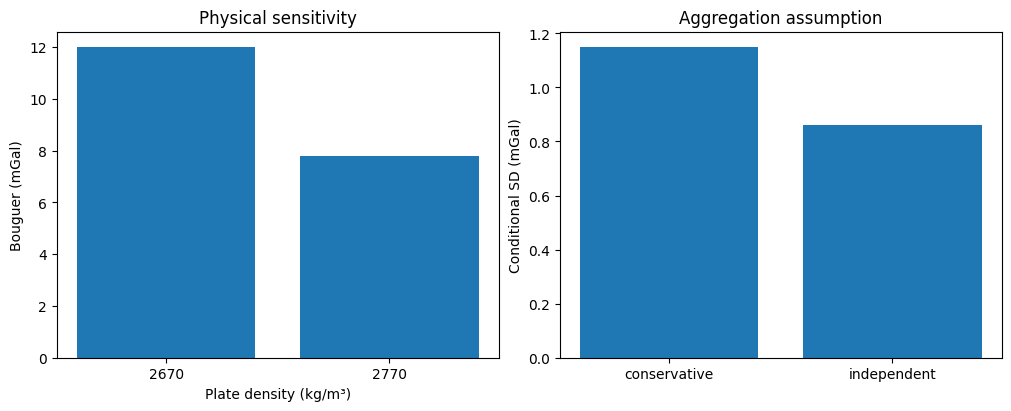

In [9]:
# Compare density and uncertainty changes from distinct pipeline runs.
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
ax.bar(['2670', '2770'], [conservative_result['qc']['derived_mgal'][0],
                         denser_plate_result['qc']['derived_mgal'][0]])
ax.set(xlabel='Plate density (kg/m³)', ylabel='Bouguer (mGal)', title='Physical sensitivity')
bx.bar(['conservative', 'independent'],
       [conservative_result['processing']['uncertainty_mgal'][0],
        independent_result['processing']['uncertainty_mgal'][0]])
bx.set(ylabel='Conditional SD (mGal)', title='Aggregation assumption')
plt.show()
density_effect = denser_plate_result['qc']['derived_mgal'][0] - conservative_result['qc']['derived_mgal'][0]

The uncertainty comparison comes from two processor executions with identical source values and physical configuration; only the named aggregation policy changes. The figure shows its numerical consequence for this station. It does not establish which policy is empirically correct, quantify covariance, or include omitted geometry and terrain uncertainty.

## Results

**Answer:** The calculated Bouguer value is 12.000000000024315 mGal; changing plate density by 100 kg/m³ changes it by −4.193586369570852 mGal. Conditional SDs are 1.148909022890369 and 0.8604422289723038 mGal, and a duplicate pass is refused.

In [10]:
# Collect calculated values and verify the refusal was observed.
print({'bouguer_mgal': conservative_result['qc']['derived_mgal'][0],
       'density_effect_mgal': density_effect,
       'conservative_sd_mgal': conservative_result['processing']['uncertainty_mgal'][0],
       'independent_sd_mgal': independent_result['processing']['uncertainty_mgal'][0],
       'duplicate_refused': bool(duplicate_refusal)})

{'bouguer_mgal': 12.000000000024315, 'density_effect_mgal': -4.193586369570852, 'conservative_sd_mgal': 1.148909022890369, 'independent_sd_mgal': 0.8604422289723038, 'duplicate_refused': True}


## Summary

M01 is an ordered, typed transformation whose outputs retain provenance and error assumptions. This control demonstrates admission, WGS84 reference, plate removal, policy sensitivity and duplicate-state refusal. Success validates only the declared synthetic arithmetic; it does not establish field suitability.

## References

- https://pubs.usgs.gov/tm/02/d04/tm2d4.pdf
- https://www.fatiando.org/harmonica/latest/api/index.html